# 24 Saat Sonrasının Sıcaklığını Tahmin Etme: Jena Hava İstasyonu Zaman Serisi
**Makine Öğrenmesi ile Probleme Uygun Çözüm Geliştirme — derin öğrenme (zaman serisi) projesi**

Geçmiş 3 günlük (72 saat) çok değişkenli hava gözleminden, **24 saat sonraki sıcaklığı** tahmin ederiz. Çalışma; iki "akıllı olmayan" taban çizgisini (süreklilik, iklimsel ortalama), doğrusal ve ağaç tabanlı ML modellerini ve üç derin modeli (LSTM, GRU, 1B-CNN) **zamana göre bölünmüş** test verisinde karşılaştırır. Derin modeller 3 tohumla eğitilir; farkların anlamlılığı gün bloklu bootstrap ile sınanır; hata mevsime ve saate göre incelenir.

**Veri:** Max Planck Biyojeokimya Enstitüsü, Jena (Almanya) hava istasyonu, 10 dakikalık gözlemler, 2009–2016, 420.551 satır × 14 değişken. Kaynak: https://www.bgc-jena.mpg.de/wetter/ (Keras örnek veri deposundaki kopya kullanıldı).

## 1. Problem Tanımı
- **Girdi:** son 72 saatin saatlik hava gözlemleri (basınç, sıcaklık, nem, buhar basıncı açığı, özgül nem, hava yoğunluğu, rüzgâr bileşenleri) + zaman bilgisi (günün ve yılın saati/günü).
- **Hedef:** 24 saat sonraki sıcaklık (°C) → **regresyon**.
- **İhtiyaç:** Enerji, tarım ve etkinlik planlamasında 1 günlük sıcaklık tahmini. Önemli soru: *Basit bir kural (yarın bugünkü gibi) yenilemeyecek kadar güçlü mü, yoksa derin model gerçek değer katıyor mu?*

In [1]:
import os, json, time, warnings, urllib.request, zipfile, io; warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf, keras
from keras import layers
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
sns.set_theme(style="whitegrid"); os.makedirs("figures", exist_ok=True); os.makedirs("data", exist_ok=True)
M = {}
YOL = "data/jena_climate_2009_2016.csv"
if not os.path.exists(YOL):      # yoksa özgün kaynaktan indir
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen("https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip").read())).extract("jena_climate_2009_2016.csv", "data")
raw = pd.read_csv(YOL); raw["Date Time"] = pd.to_datetime(raw["Date Time"], format="%d.%m.%Y %H:%M:%S"); raw = raw.set_index("Date Time")
print(raw.shape, raw.index.min(), "→", raw.index.max()); M["n_ham"] = len(raw)

(420551, 14) 2009-01-01 00:10:00 → 2017-01-01 00:00:00


## 2. Veri Seti
420.551 gözlem, 14 değişken, 10 dakikalık aralık. Hedef değişken sıcaklık (`T (degC)`). Bağımlı/yinelenen bilgi içeren sütunlar var (ör. `Tpot`, `Tdew`, `VPmax`, `H2OC`); bunlar sıcaklıktan türetildiği için çıkarılır. **Sınıf dengesi** kavramı regresyonda yoktur; bunun yerine hedefin dağılımı ve mevsimselliği incelenir.

In [2]:
print(raw.isnull().sum().sum(), "eksik değer")
print("Rüzgâr hızı = -9999 olan satır:", int((raw["wv (m/s)"] < -100).sum()), "/", int((raw["max. wv (m/s)"] < -100).sum()))
display(raw[["T (degC)", "p (mbar)", "rh (%)", "wv (m/s)"]].describe().round(1))

0 eksik değer
Rüzgâr hızı = -9999 olan satır: 18 / 20


,T (degC),p (mbar),rh (%),wv (m/s)
count,420551.0,420551.0,420551.0,420551.0
mean,9.5,989.2,76.0,1.7
std,8.4,8.4,16.5,65.4
min,-23.0,913.6,13.0,-9999.0
25%,3.4,984.2,65.2,1.0
50%,9.4,989.6,79.3,1.8
75%,15.5,994.7,89.4,2.9
max,37.3,1015.4,100.0,28.5


**Temizleme:** `wv` ve `max. wv` sütunlarında fiziksel olarak imkânsız `-9999` değerleri (sensör hatası kodu) vardır. Bunlar eksik değer yapılıp doğrusal enterpolasyonla doldurulur. Rüzgâr yönü (derece) döngüsel olduğu için doğrudan kullanılmaz; rüzgâr hızıyla birlikte **x–y bileşenlerine** çevrilir. Veri 10 dakikalıktan **saatliğe** (ortalama) indirilir (tahmin ufku saat bazlıdır; 6 kat küçültür).

In [3]:
d = raw.copy()
for col in ["wv (m/s)", "max. wv (m/s)"]: d.loc[d[col] < -100, col] = np.nan
d = d.interpolate(limit_direction="both")
rad = np.deg2rad(d["wd (deg)"]); d["wx"] = d["wv (m/s)"] * np.cos(rad); d["wy"] = d["wv (m/s)"] * np.sin(rad)
KOL = ["T (degC)", "p (mbar)", "rh (%)", "VPdef (mbar)", "sh (g/kg)", "rho (g/m**3)", "wx", "wy"]
h = d[KOL].resample("1h").mean().interpolate()
print(h.shape, h.isnull().sum().sum(), "eksik")
M["n_saatlik"] = len(h)

(70129, 8) 0 eksik


## 3. Veri Keşfi (4 görselleştirme)

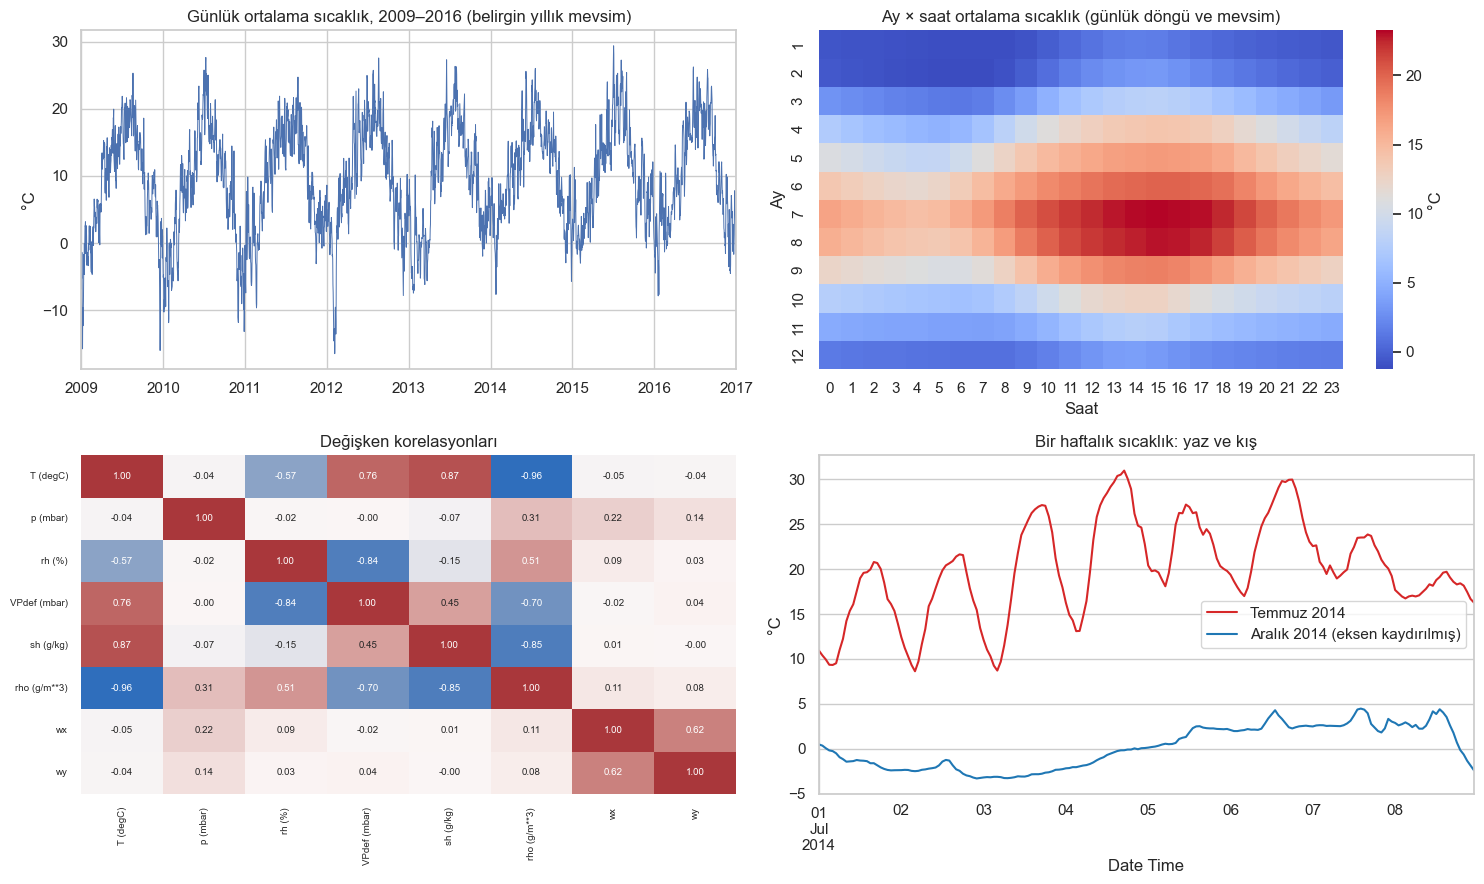

Sıcaklık ortalama/std: 9.4 8.4
T ile korelasyon: {'p (mbar)': -0.04, 'rh (%)': -0.57, 'VPdef (mbar)': 0.76, 'sh (g/kg)': 0.87, 'rho (g/m**3)': -0.96, 'wx': -0.05, 'wy': -0.04}


In [4]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
h["T (degC)"].resample("1D").mean().plot(ax=ax[0, 0], lw=.7); ax[0, 0].set_title("Günlük ortalama sıcaklık, 2009–2016 (belirgin yıllık mevsim)"); ax[0, 0].set_ylabel("°C"); ax[0, 0].set_xlabel("")
piv = h.assign(ay=h.index.month, saat=h.index.hour).pivot_table(index="ay", columns="saat", values="T (degC)", aggfunc="mean")
sns.heatmap(piv, cmap="coolwarm", ax=ax[0, 1], cbar_kws={"label": "°C"}); ax[0, 1].set_title("Ay × saat ortalama sıcaklık (günlük döngü ve mevsim)"); ax[0, 1].set_xlabel("Saat"); ax[0, 1].set_ylabel("Ay")
sns.heatmap(h.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[1, 0], annot_kws={"size": 7}, cbar=False); ax[1, 0].set_title("Değişken korelasyonları"); ax[1, 0].tick_params(labelsize=7)
h.loc["2014-07-01":"2014-07-08", "T (degC)"].plot(ax=ax[1, 1], color="tab:red", label="Temmuz 2014"); h.loc["2014-12-01":"2014-12-08", "T (degC)"].set_axis(h.loc["2014-07-01":"2014-07-08"].index).plot(ax=ax[1, 1], color="tab:blue", label="Aralık 2014 (eksen kaydırılmış)")
ax[1, 1].set_title("Bir haftalık sıcaklık: yaz ve kış"); ax[1, 1].set_ylabel("°C"); ax[1, 1].legend()
plt.tight_layout(); plt.savefig("figures/eda.png", dpi=150); plt.show()
print("Sıcaklık ortalama/std:", round(h["T (degC)"].mean(), 1), round(h["T (degC)"].std(), 1))
print("T ile korelasyon:", h.corr()["T (degC)"].drop("T (degC)").round(2).to_dict())

**Gözlemler.** (1) Sıcaklık güçlü bir **yıllık döngüye** (kış ≈ 0 °C, yaz ≈ 20 °C) ve **günlük döngüye** (öğleden sonra en yüksek) sahip; tahmin bu iki döngüyü yakalamalı. (2) `T` ile `sh` (özgün nem) ve `VPdef` pozitif, `rh` ile negatif ilişkili; bazı özellikler birbirini tekrar eder (çoklu doğrusallık). (3) Günlük döngü yüzünden "24 saat önceki değer" doğal olarak güçlü bir tahmindir; bu yüzden **süreklilik (persistence) taban çizgisini yenmek zor** olacaktır.

## 4. Veri Ön İşleme
- **Zaman özellikleri:** günün saati ve yılın günü için sin/cos (döngüsel) kodlama → 4 kanal.
- **Pencereleme:** 72 saatlik girdi penceresi → 24 saat sonraki sıcaklık. Örnek sayısı ≈ 70 bin.
- **Zamana göre bölme (karıştırma yok, sızıntı yok):** hedef zamanı **2009–2014 eğitim**, **2015 doğrulama**, **2016 test**. Rastgele bölme geleceği geçmişe sızdırır; zaman serisinde yanlıştır.
- **Ölçekleme:** ortalama/std yalnızca **eğitim** döneminden hesaplanır.

In [5]:
W, UFUK = 72, 24
zt = h.index
saat = 2 * np.pi * zt.hour / 24; yil = 2 * np.pi * zt.dayofyear / 365.25
X_all = np.column_stack([h.values, np.sin(saat), np.cos(saat), np.sin(yil), np.cos(yil)]).astype("float32")
KANAL = KOL + ["sin_saat", "cos_saat", "sin_yil", "cos_yil"]; C_ = X_all.shape[1]
hedef_zamani = zt[W - 1 + UFUK:]                                     # örnek i: pencere [i, i+W), hedef = i+W-1+UFUK
N = len(X_all) - (W - 1) - UFUK
egitim = hedef_zamani < "2015-01-01"; dogrulama = (hedef_zamani >= "2015-01-01") & (hedef_zamani < "2016-01-01"); test = hedef_zamani >= "2016-01-01"
mu, sd = X_all[: egitim.sum() + W - 1 + UFUK].mean(0), X_all[: egitim.sum() + W - 1 + UFUK].std(0)
Xs = (X_all - mu) / sd
pencere = sliding_window_view(Xs, W, axis=0).transpose(0, 2, 1)[:N]  # (N, W, C)
y_raw = h["T (degC)"].values[W - 1 + UFUK:][:N]; T_son = h["T (degC)"].values[W - 1:][:N]   # T_son: pencerenin son saatindeki sıcaklık
y_sc = (y_raw - mu[0]) / sd[0]
tr, va, te = np.where(egitim[:N])[0], np.where(dogrulama[:N])[0], np.where(test[:N])[0]
print("pencere:", pencere.shape, "| eğitim/doğrulama/test:", len(tr), len(va), len(te))
M.update(n_tr=int(len(tr)), n_va=int(len(va)), n_te=int(len(te)))

pencere: (70034, 72, 12) | eğitim/doğrulama/test: 52489 8760 8785


## 5. Model Seçimi / Tasarımı
| Model | Neden? |
|---|---|
| Süreklilik (persistence) | "Yarın bugünün aynısı": en basit kural; her modelin yenmesi gereken referans |
| İklimsel ortalama | (ay, saat) bazında eğitim dönemi ortalaması: mevsim ve günlük döngüyü bilir, hava durumunu bilmez |
| Ridge (doğrusal) | 72×12 düzleştirilmiş pencere üzerinde düzenlileştirilmiş doğrusal regresyon |
| HistGradientBoosting | Pencereden türetilmiş özetler (son değer, 6/12/24/48 saat önce, ortalama, std) üzerinde doğrusal olmayan ağaç topluluğu |
| **LSTM / GRU** | Zaman bağımlılığını öğrenen yinelemeli ağlar (48 birim → Dense(32) → Dense(1)) |
| **1B-CNN** | Zamansal örüntü filtreleri (Conv1D 32→64, çekirdek 5, MaxPool, GlobalAvgPool) |

**Derin model tasarımı:** aktivasyon ReLU (Dense/Conv), yinelemeli katmanlarda tanh/sigmoid (varsayılan); çıkış 1 nöron, **doğrusal** aktivasyon (regresyon); **kayıp:** MSE; **optimizer:** Adam (lr 1e-3); düzenlileştirme: Dropout(0,2).

In [6]:
def ozet_ozellik(Xw):
    son, p6, p12, p24, p48 = Xw[:, -1], Xw[:, -7], Xw[:, -13], Xw[:, -25], Xw[:, -49]
    return np.hstack([son, son - p6, son - p12, son - p24, p24 - p48, Xw[:, -24:].mean(1), Xw[:, -24:].std(1), Xw.mean(1)])
F_ozet, F_duz = ozet_ozellik(pencere), pencere.reshape(N, -1)
def metrik(y, p):
    e = y - p; return dict(MAE=float(np.abs(e).mean()), RMSE=float(np.sqrt((e ** 2).mean())), R2=float(1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum()))
TAHMIN = {}; SURE = {}
TAHMIN["Süreklilik (persistence)"] = T_son[te]
clim = pd.Series(y_raw[tr]).groupby([hedef_zamani[:N][tr].month, hedef_zamani[:N][tr].hour]).mean()
TAHMIN["İklimsel ortalama"] = np.array([clim[(a, b)] for a, b in zip(hedef_zamani[:N][te].month, hedef_zamani[:N][te].hour)])
t0 = time.time(); rg = Ridge(alpha=300).fit(F_duz[tr], y_sc[tr]); TAHMIN["Ridge"] = rg.predict(F_duz[te]) * sd[0] + mu[0]; SURE["Ridge"] = time.time() - t0
t0 = time.time(); hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=.06, max_leaf_nodes=24, l2_regularization=1., random_state=0).fit(F_ozet[tr], y_sc[tr]); TAHMIN["HistGradientBoosting"] = hgb.predict(F_ozet[te]) * sd[0] + mu[0]; SURE["HGB"] = time.time() - t0
for k, v in TAHMIN.items(): print(f"{k:28s}", {a: round(b, 3) for a, b in metrik(y_raw[te], v).items()})
# Ridge alpha seçimi doğrulama kümesinde (test'e bakmadan)
for a in (30, 300, 3000): print("Ridge alpha", a, "doğrulama MAE:", round(np.abs((Ridge(alpha=a).fit(F_duz[tr], y_sc[tr]).predict(F_duz[va]) * sd[0] + mu[0]) - y_raw[va]).mean(), 3))

Süreklilik (persistence)     {'MAE': 2.437, 'RMSE': 3.203, 'R2': 0.847}
İklimsel ortalama            {'MAE': 3.287, 'RMSE': 4.158, 'R2': 0.742}
Ridge                        {'MAE': 2.263, 'RMSE': 2.882, 'R2': 0.876}
HistGradientBoosting         {'MAE': 2.185, 'RMSE': 2.789, 'R2': 0.884}


Ridge alpha 30 doğrulama MAE: 2.489


Ridge alpha 300 doğrulama MAE: 2.503


Ridge alpha 3000 doğrulama MAE: 2.521


## 6. Model Eğitimi (derin modeller)
- **Doğrulama yaklaşımı:** 2015 yılı doğrulama kümesidir; `EarlyStopping(patience=3, restore_best_weights=True)`.
- **Epoch / batch size:** en fazla 12 epoch, batch size 256. CPU'da eğitim süresi nedeniyle bütçe sınırlıdır.
- Her model **3 tohumla** (0, 1, 2) eğitilir; sonuçlar ortalama ± std olarak verilir ve ayrıca 3 tohumun ortalaması alınan **topluluk** (ensemble) tahmini raporlanır.

In [7]:
def model_kur(tur):
    g = keras.Input((W, C_)); x = g
    if tur == "LSTM": x = layers.LSTM(48)(x)
    elif tur == "GRU": x = layers.GRU(48)(x)
    else:
        x = layers.MaxPooling1D(2)(layers.Conv1D(32, 5, padding="same", activation="relu")(x)); x = layers.GlobalAveragePooling1D()(layers.Conv1D(64, 5, padding="same", activation="relu")(x))
    x = layers.Dense(32, activation="relu")(layers.Dropout(.2)(x))
    return keras.Model(g, layers.Dense(1)(x))
GECMIS, TOH = {}, {}
for tur in ["LSTM", "GRU", "1B-CNN"]:
    TOH[tur] = []; GECMIS[tur] = []
    for tohum in (0, 1, 2):
        keras.utils.set_random_seed(tohum); mdl = model_kur(tur); mdl.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
        t0 = time.time(); h_ = mdl.fit(pencere[tr], y_sc[tr], validation_data=(pencere[va], y_sc[va]), epochs=12, batch_size=256, verbose=0, callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
        TOH[tur].append(mdl.predict(pencere[te], batch_size=1024, verbose=0)[:, 0] * sd[0] + mu[0]); GECMIS[tur].append(h_.history)
        print(f"{tur} tohum {tohum}: {len(h_.history['loss'])} epoch, {time.time() - t0:.0f} sn, val_mse={min(h_.history['val_loss']):.4f}, test MAE={np.abs(TOH[tur][-1] - y_raw[te]).mean():.3f}")
        SURE[tur] = SURE.get(tur, 0) + time.time() - t0

LSTM tohum 0: 6 epoch, 39 sn, val_mse=0.1234, test MAE=2.123


LSTM tohum 1: 7 epoch, 51 sn, val_mse=0.1257, test MAE=2.169


LSTM tohum 2: 8 epoch, 68 sn, val_mse=0.1252, test MAE=2.152


GRU tohum 0: 12 epoch, 87 sn, val_mse=0.1217, test MAE=2.073


GRU tohum 1: 11 epoch, 87 sn, val_mse=0.1220, test MAE=2.133


GRU tohum 2: 11 epoch, 87 sn, val_mse=0.1265, test MAE=2.121


1B-CNN tohum 0: 10 epoch, 12 sn, val_mse=0.1450, test MAE=2.354


1B-CNN tohum 1: 12 epoch, 14 sn, val_mse=0.1353, test MAE=2.322


1B-CNN tohum 2: 12 epoch, 15 sn, val_mse=0.1373, test MAE=2.344


## 7. Model Değerlendirme (test: 2016)

In [8]:
rows = []
for ad in ["Süreklilik (persistence)", "İklimsel ortalama", "Ridge", "HistGradientBoosting"]:
    r = metrik(y_raw[te], TAHMIN[ad]); rows.append(dict(Model=ad, **r, MAE_std=0.0))
for tur in ["LSTM", "GRU", "1B-CNN"]:
    ms = [metrik(y_raw[te], p) for p in TOH[tur]]
    rows.append(dict(Model=tur + " (3 tohum ort.)", MAE=np.mean([a["MAE"] for a in ms]), RMSE=np.mean([a["RMSE"] for a in ms]), R2=np.mean([a["R2"] for a in ms]), MAE_std=np.std([a["MAE"] for a in ms])))
    TAHMIN[tur + " topluluk"] = np.mean(TOH[tur], 0); rows.append(dict(Model=tur + " topluluk (3 tohum)", **metrik(y_raw[te], TAHMIN[tur + " topluluk"]), MAE_std=0.0))
tablo = pd.DataFrame(rows).set_index("Model"); base = tablo.loc["Süreklilik (persistence)", "MAE"]; tablo["MAE_skill_vs_persistence"] = 1 - tablo["MAE"] / base
display(tablo.round(3)); M["tablo"] = tablo.round(4).reset_index().to_dict("records")

,MAE,RMSE,R2,MAE_std,MAE_skill_vs_persistence
Model,,,,,
Süreklilik (persistence),2.437,3.203,0.847,0.000,0.000
İklimsel ortalama,3.287,4.158,0.742,0.000,-0.349
Ridge,2.263,2.882,0.876,0.000,0.071
HistGradientBoosting,2.185,2.789,0.884,0.000,0.104
LSTM (3 tohum ort.),2.148,2.742,0.888,0.019,0.118
LSTM topluluk (3 tohum),2.121,2.705,0.891,0.000,0.130
GRU (3 tohum ort.),2.109,2.681,0.893,0.026,0.134
GRU topluluk (3 tohum),2.089,2.657,0.895,0.000,0.143
1B-CNN (3 tohum ort.),2.340,2.945,0.871,0.014,0.040


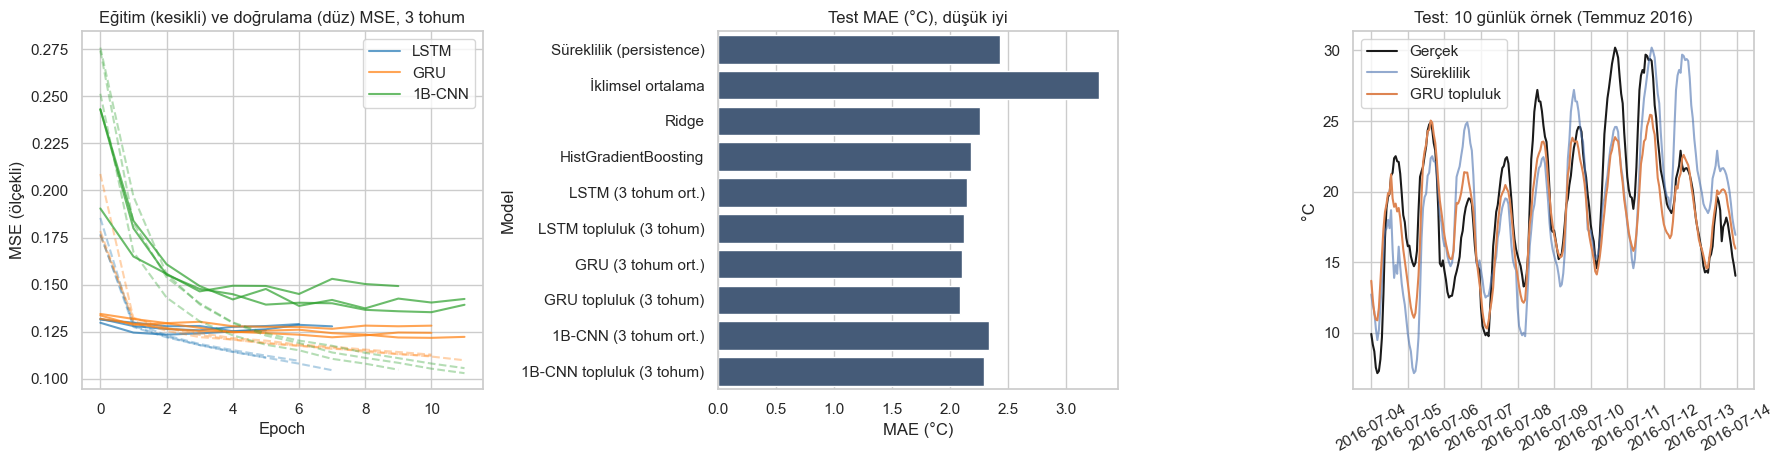

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for tur, col in zip(TOH, ["tab:blue", "tab:orange", "tab:green"]):
    for i, hh in enumerate(GECMIS[tur]):
        ax[0].plot(hh["val_loss"], color=col, alpha=.7, label=tur if i == 0 else None); ax[0].plot(hh["loss"], "--", color=col, alpha=.35)
ax[0].set_title("Eğitim (kesikli) ve doğrulama (düz) MSE, 3 tohum"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("MSE (ölçekli)"); ax[0].legend()
t_ = tablo.reset_index(); sns.barplot(data=t_, y="Model", x="MAE", ax=ax[1], color="#3d5a80"); ax[1].set_title("Test MAE (°C), düşük iyi"); ax[1].set_xlabel("MAE (°C)")
gz = hedef_zamani[:N][te]; pbas = pd.Timestamp("2016-07-04"); mk = (gz >= pbas) & (gz < pbas + pd.Timedelta(days=10))
ax[2].plot(gz[mk], y_raw[te][mk], "k", label="Gerçek"); ax[2].plot(gz[mk], TAHMIN["Süreklilik (persistence)"][mk], alpha=.6, label="Süreklilik"); ax[2].plot(gz[mk], TAHMIN["GRU topluluk"][mk], label="GRU topluluk")
ax[2].set_title("Test: 10 günlük örnek (Temmuz 2016)"); ax[2].set_ylabel("°C"); ax[2].legend(); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figures/egitim_ve_karsilastirma.png", dpi=150); plt.show()

## 8. İstatistiksel Anlamlılık: En iyi derin model gerçekten Ridge'den iyi mi?
Ardışık saatlik hatalar ilişkilidir; bu yüzden **gün bloklu eşleştirilmiş bootstrap** kullanılır (her gün bir blok). İki modelin günlük ortalama mutlak hata farkı için %95 güven aralığı hesaplanır.

In [10]:
def blok_bootstrap(p1, p2, y, zaman, n=3000, tohum=0):
    gun = pd.Series(np.abs(y - p1) - np.abs(y - p2)).groupby(zaman.normalize().values).mean().values   # fark: model1 - model2 (negatif = model1 daha iyi)
    r = np.random.default_rng(tohum); ort = [r.choice(gun, len(gun)).mean() for _ in range(n)]
    return float(gun.mean()), [float(np.percentile(ort, 2.5)), float(np.percentile(ort, 97.5))]
dl = [k for k in tablo.index if "topluluk" in k]; en_iyi_dl = min(dl, key=lambda k: tablo.loc[k, "MAE"]); print("En iyi derin model (topluluk):", en_iyi_dl)
anahtar = en_iyi_dl.replace(" topluluk (3 tohum)", "") + " topluluk"
fark_ridge = blok_bootstrap(TAHMIN[anahtar], TAHMIN["Ridge"], y_raw[te], gz)
fark_pers = blok_bootstrap(TAHMIN[anahtar], TAHMIN["Süreklilik (persistence)"], y_raw[te], gz)
fark_hgb = blok_bootstrap(TAHMIN[anahtar], TAHMIN["HistGradientBoosting"], y_raw[te], gz)
for ad, f in (("Ridge", fark_ridge), ("Persistence", fark_pers), ("HGB", fark_hgb)): print(f"{en_iyi_dl} − {ad}: ΔMAE = {f[0]:+.3f} °C, %95 GA [{f[1][0]:+.3f}, {f[1][1]:+.3f}]")
M["bootstrap"] = dict(model=en_iyi_dl, ridge=fark_ridge, persistence=fark_pers, hgb=fark_hgb)

En iyi derin model (topluluk): GRU topluluk (3 tohum)
GRU topluluk (3 tohum) − Ridge: ΔMAE = -0.173 °C, %95 GA [-0.235, -0.117]
GRU topluluk (3 tohum) − Persistence: ΔMAE = -0.343 °C, %95 GA [-0.442, -0.241]
GRU topluluk (3 tohum) − HGB: ΔMAE = -0.098 °C, %95 GA [-0.150, -0.048]


## 9. Hata Analizi

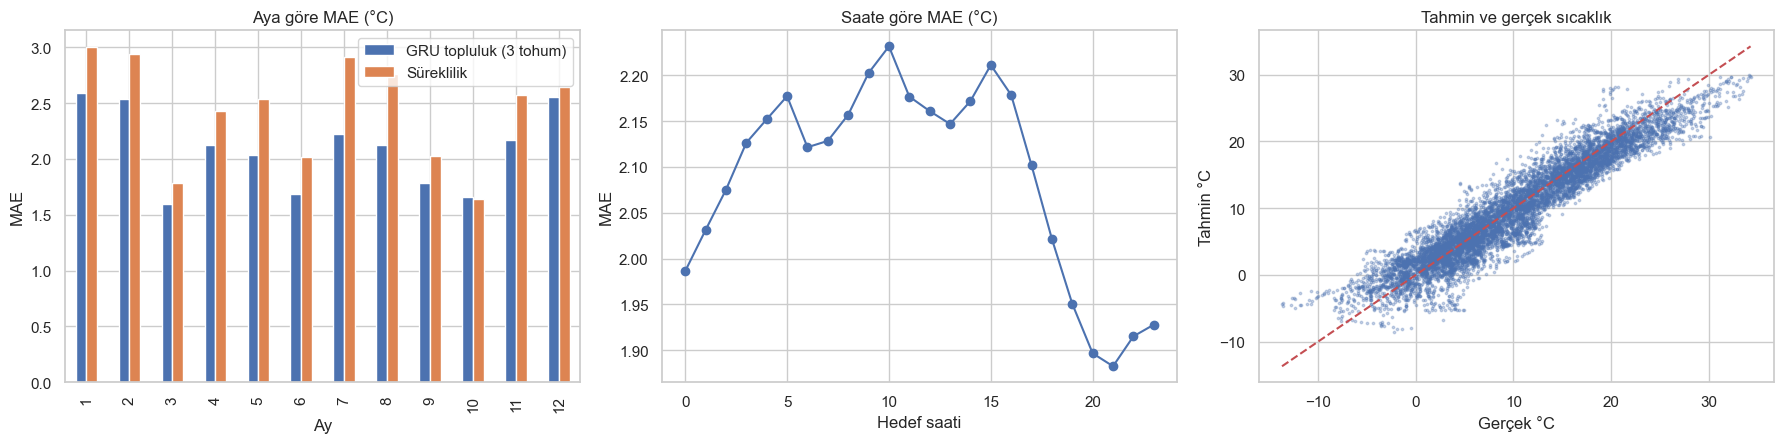

Aya göre MAE: {1: 2.59, 2: 2.53, 3: 1.6, 4: 2.12, 5: 2.04, 6: 1.68, 7: 2.22, 8: 2.13, 9: 1.78, 10: 1.66, 11: 2.17, 12: 2.55}
En kötü 5 gün: {Timestamp('2016-02-01 00:00:00'): 6.78, Timestamp('2016-02-21 00:00:00'): 6.02, Timestamp('2016-01-08 00:00:00'): 5.97, Timestamp('2016-12-01 00:00:00'): 5.86, Timestamp('2016-01-23 00:00:00'): 5.43}
Hata ortalaması (yanlılık): -0.182 | hata std: 2.651 | |hata|>5°C oranı: 0.0582


In [11]:
p_en = TAHMIN[anahtar]; e = p_en - y_raw[te]
hz = pd.DataFrame({"hata": e, "mut": np.abs(e), "ay": gz.month, "saat": gz.hour, "gercek": y_raw[te], "pers": np.abs(TAHMIN["Süreklilik (persistence)"] - y_raw[te])})
ay = hz.groupby("ay")[["mut", "pers"]].mean(); saat = hz.groupby("saat")["mut"].mean()
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ay.rename(columns={"mut": en_iyi_dl, "pers": "Süreklilik"}).plot.bar(ax=ax[0]); ax[0].set_title("Aya göre MAE (°C)"); ax[0].set_xlabel("Ay"); ax[0].set_ylabel("MAE")
saat.plot(ax=ax[1], marker="o"); ax[1].set_title("Saate göre MAE (°C)"); ax[1].set_xlabel("Hedef saati"); ax[1].set_ylabel("MAE")
ax[2].scatter(y_raw[te], p_en, s=3, alpha=.3); lim = [y_raw[te].min(), y_raw[te].max()]; ax[2].plot(lim, lim, "r--"); ax[2].set_title("Tahmin ve gerçek sıcaklık"); ax[2].set_xlabel("Gerçek °C"); ax[2].set_ylabel("Tahmin °C")
plt.tight_layout(); plt.savefig("figures/hata_analizi.png", dpi=150); plt.show()
gunluk = hz.assign(gun=gz.normalize().values).groupby("gun")["mut"].mean().sort_values(ascending=False)
print("Aya göre MAE:", ay["mut"].round(2).to_dict()); print("En kötü 5 gün:", gunluk.head(5).round(2).to_dict())
print("Hata ortalaması (yanlılık):", round(float(e.mean()), 3), "| hata std:", round(float(e.std()), 3), "| |hata|>5°C oranı:", round(float((np.abs(e) > 5).mean()), 4))
M["hata"] = dict(ay_mae=ay["mut"].round(3).to_dict(), saat_mae={int(k): round(float(v), 3) for k, v in saat.items()}, en_kotu_gunler={str(k.date()): round(float(v), 2) for k, v in gunluk.head(5).items()}, yanlilik=float(e.mean()), buyuk_hata_orani=float((np.abs(e) > 5).mean()), ay_pers=ay["pers"].round(3).to_dict())
M["sure_sn"] = {k: round(v) for k, v in SURE.items()}
json.dump(M, open("metrics.json", "w"), ensure_ascii=False, indent=1, default=float)

## 10. Sonuç
Yorum ve değerlendirme rapor dosyasında (`Rapor.docx`).